# Chapter 6: First-party signals

This notebook walks through `first_party_signals.py` on the extended synthetic dataset (`disputes_extended.csv`, built by `make_data.py`). It covers dispute concentration, per-cardholder signals, tiers with reasons, and the contest threshold of Table 6.3. All data are synthetic.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from first_party_signals import (AS_OF, load, first_party_only, concentration, build_signals,
                                 score_signals, contest_threshold, threshold_table)
pd.set_option('display.width', 140)
disputes = load()
print(f"Disputes: {len(disputes):,}; disputing cardholders: {disputes['card_id'].nunique():,}")
disputes.head()

Disputes: 5,000; disputing cardholders: 4,300


,case_id,opened_at,closed_at,product,network,family,amount,represented,outcome,recovered,net_loss,handling_cost,card_id,merchant_id,reason,delivery_confirmed
0,D00001,2025-10-01 01:25:54,2025-11-08 06:46:14,debit_card,visa,defective,123.81,False,accepted,123.81,0.00,19.36,c3967,m0363,not_received,False
1,D00002,2025-10-01 01:27:30,2025-10-15 08:42:09,debit_card,mastercard,unauthorized,226.99,False,written_off,0.00,226.99,10.43,c3334,m0564,unauthorized,False
2,D00003,2025-10-01 02:45:30,2025-10-21 13:43:13,credit_card,mastercard,defective,101.75,False,denied,0.00,0.00,19.41,c1152,m0120,not_received,False
3,D00004,2025-10-01 03:33:10,2025-11-07 02:58:04,credit_card,visa,defective,97.06,False,denied,0.00,0.00,7.40,c2713,m0218,not_as_described,False
4,D00005,2025-10-01 03:46:28,2025-11-05 16:38:08,credit_card,mastercard,unauthorized,143.14,False,accepted,143.14,0.00,13.34,c1884,m0397,unauthorized,False


## Concentration: a few cardholders raise a large share of disputes

Top 3% of disputing cardholders raise 11.1% of all disputes


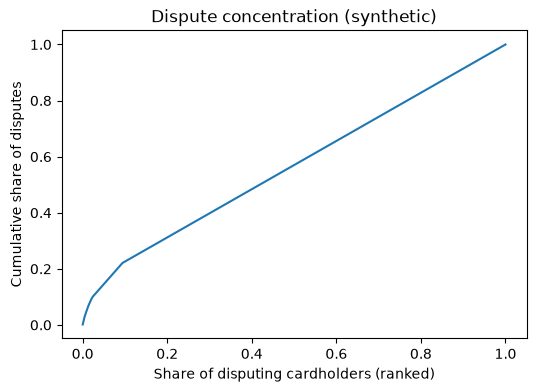

In [2]:
print(f'Top 3% of disputing cardholders raise {concentration(disputes):.1%} of all disputes')
counts = disputes['card_id'].value_counts().sort_values(ascending=False)
share = counts.cumsum() / counts.sum()
ax = (share.reset_index(drop=True)
      .set_axis((pd.RangeIndex(len(share)) + 1) / len(share))
      .plot(figsize=(6, 4)))
ax.set_xlabel('Share of disputing cardholders (ranked)')
ax.set_ylabel('Cumulative share of disputes')
ax.set_title('Dispute concentration (synthetic)')
plt.show()

## Signals and tiers

Signals are built on first-party claims only, over a 90-day window. Without that family gate, bursts of unauthorized claims from compromised cards would look like misuse.

In [3]:
scored = score_signals(build_signals(first_party_only(disputes), AS_OF))
print(f'Cardholders scored as of {AS_OF[:10]}: {len(scored):,}')
scored['tier'].value_counts().reindex(['standard', 'clarify', 'review'])

Cardholders scored as of 2026-09-30: 416


tier
standard    398
clarify       6
review       12
Name: count, dtype: int64

In [4]:
cols = ['claims', 'not_received_share', 'top_merchant_share', 'proof_rate',
        'median_gap_days', 'points', 'tier']
# Table 6.5: sample output of the signal pipeline
scored.loc[['c741', 'c2677', 'c3578'], cols].round(2)

,claims,not_received_share,top_merchant_share,proof_rate,median_gap_days,points,tier
card_id,,,,,,,
c741,6,0.83,0.17,0.67,6.0,7,review
c2677,3,1.00,0.33,0.33,6.5,4,clarify
c3578,2,0.50,0.50,1.00,57.0,2,standard


In [5]:
# Worked example: four not-received claims at four merchants
scored.loc[['c1024'], cols + ['reasons']].round(2)

,claims,not_received_share,top_merchant_share,proof_rate,median_gap_days,points,tier,reasons
card_id,,,,,,,,
c1024,4,1.0,0.25,0.75,7.0,7,review,4+ claims in window; mostly not-received; deli...


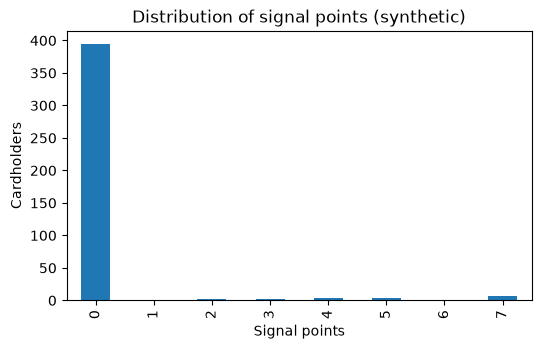

In [6]:
ax = scored['points'].value_counts().sort_index().plot.bar(figsize=(6, 3.5))
ax.set_xlabel('Signal points'); ax.set_ylabel('Cardholders')
ax.set_title('Distribution of signal points (synthetic)')
plt.show()

## Contest threshold

Contest a claim of amount A only when p_win × A exceeds the handling cost plus the expected loss of relationship value: A > (c + q·V) / p.

In [7]:
print(f'Threshold with no relationship value: ${contest_threshold(0.42, 40, 0.05, 0):,.0f}')
threshold_table()  # Table 6.3 (c = $40, q = 0.05)

Threshold with no relationship value: $95


,Cardholder,Claim A,V,Threshold p=0.42,Threshold p=0.70,Treatment
0,"A: new, low margin",240,150,113,68,"Above both lines: review, then contest"
1,"B: long-tenured, high margin",95,2000,333,200,Below both lines: accept and clarify
2,"C: established, mid margin",186,600,167,100,Close to the line: analyst decides
